
# 03 — Preliminary RetinaNet Experiment

This notebook analyses the preliminary RetinaNet ResNet50-FPN V2 experiment conducted on the cleaned five-class pork rasher packaging dataset.

The experiment evaluated five categories:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle

The original model was trained for 15 epochs using SGD with a learning rate of 0.005, momentum of 0.9 and weight decay of 0.0005.

This notebook reuses the original trained checkpoint and saved experiment records. It reproduces validation evaluation, class-specific analysis, confidence-threshold comparison and confusion matrices without retraining.

The original training implementation will be retained in a separate optional training script.


In [1]:

# Install dependencies for evaluating saved RetinaNet checkpoints.
%pip install -q torch torchvision torchmetrics pycocotools pandas pyyaml matplotlib pillow


In [2]:

# Load the original five-class RetinaNet experiment and shared project code.

import gc
import json
import os
import random
import subprocess
import sys

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch

from IPython.display import display
from google.colab import drive
from torch.utils.data import DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.ops import box_iou

REPO_URL = "https://github.com/daniellawjmcc/MMA3001_Project.git"
REPO_ROOT = Path("/content/MMA3001_Project_repo")

DRIVE_ROOT = Path("/content/gdrive_new")
DEFAULT_PROJECT_ROOT = DRIVE_ROOT / "MyDrive" / "MMA3001_Project"

if not DEFAULT_PROJECT_ROOT.is_dir():
    drive.mount(str(DRIVE_ROOT))

if not REPO_ROOT.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )

source_path = str(REPO_ROOT / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)

from mma3001.config import (
    FIVE_CLASS_NAMES,
    SEED,
    find_project_root,
    get_checkpoint_path,
    get_dataset_path,
    get_run_path,
    set_seed,
)
from mma3001.dataset import (
    YoloDetectionDataset,
    detection_collate_fn,
    load_class_names,
)
from mma3001.metrics import (
    precision_recall_f1,
    summarise_confusion_matrix,
)
from mma3001.evaluation import (
    detection_confusion_matrix,
    evaluate_thresholds,
    select_best_threshold,
    correct_detections_table,
    per_class_recall_table,
)
from mma3001.plotting import (
    plot_confusion_matrix,
    plot_confusion_matrices,
    plot_threshold_metrics,
    plot_training_history,
    show_saved_figure,
)
from mma3001.models import load_experiment_model

set_seed(SEED)

project_root = find_project_root(
    os.environ.get(
        "MMA3001_PROJECT_ROOT",
        str(DEFAULT_PROJECT_ROOT),
    )
)

dataset_root = get_dataset_path(
    project_root,
    four_class=False,
)

run_dir = get_run_path(
    project_root,
    "retinanet_baseline",
)

checkpoint_path = get_checkpoint_path(
    project_root,
    "retinanet_baseline",
)

yolo_classes = load_class_names(dataset_root)
CLASS_NAMES = list(FIVE_CLASS_NAMES)

if [yolo_classes[i] for i in range(5)] != CLASS_NAMES:
    raise ValueError(
        "The original five-class mapping does not match the dataset."
    )

# Torchvision training used class IDs 1–5.
class_names = {
    index + 1: name
    for index, name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)
MATRIX_LABELS = CLASS_NAMES + ["background"]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", project_root)
print("Dataset:", dataset_root)
print("Run:", run_dir)
print("Checkpoint:", checkpoint_path)
print("Classes:", class_names)
print("Device:", device)


Mounted at /content/gdrive_new
Project: /content/gdrive_new/MyDrive/MMA3001_Project
Dataset: /content/gdrive_new/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_clean
Run: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1
Checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1/best.pt
Classes: {1: 'loose-meat', 2: 'packaging-error', 3: 'twisted-meat', 4: 'unsealed', 5: 'wrinkle'}
Device: cuda



## 1. Dataset Conversion and Annotation Verification

The original dataset stores annotations in normalised YOLO format:

`class_id x_center y_center width height`

RetinaNet requires absolute pixel coordinates:

`x_min y_min x_max y_max`

The class indices are shifted by one to match the original Torchvision training implementation.

The converted annotations are visualised using the original training images. No source images or labels are modified.


In [3]:

# Load the training and validation splits using shared YOLO conversion.

train_dataset = YoloDetectionDataset(
    dataset_root=dataset_root,
    split="train",
    label_offset=1,
)

valid_dataset = YoloDetectionDataset(
    dataset_root=dataset_root,
    split="valid",
    label_offset=1,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate_fn,
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Class mapping:", train_dataset.class_names)

assert len(train_dataset) == 3343
assert len(valid_dataset) == 123

print("Five-class dataset successfully loaded.")


Training images: 3343
Validation images: 123
Class mapping: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed', 4: 'wrinkle'}
Five-class dataset successfully loaded.


Image tensor shape: torch.Size([3, 540, 720])
Bounding boxes: tensor([[614.4500, 386.6700, 656.6700, 436.6700]])
Class labels: tensor([2])


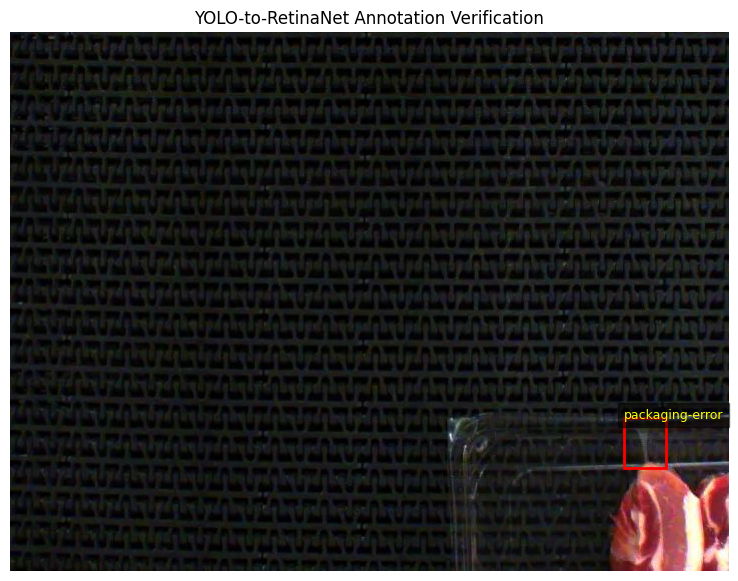

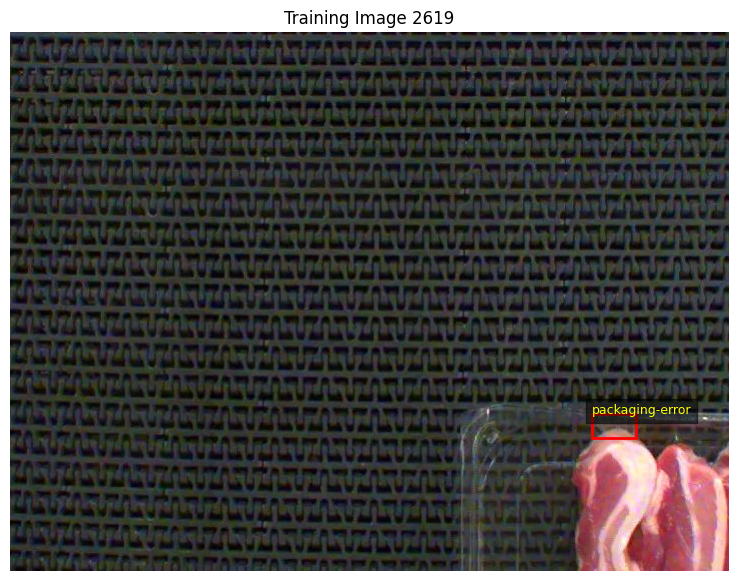

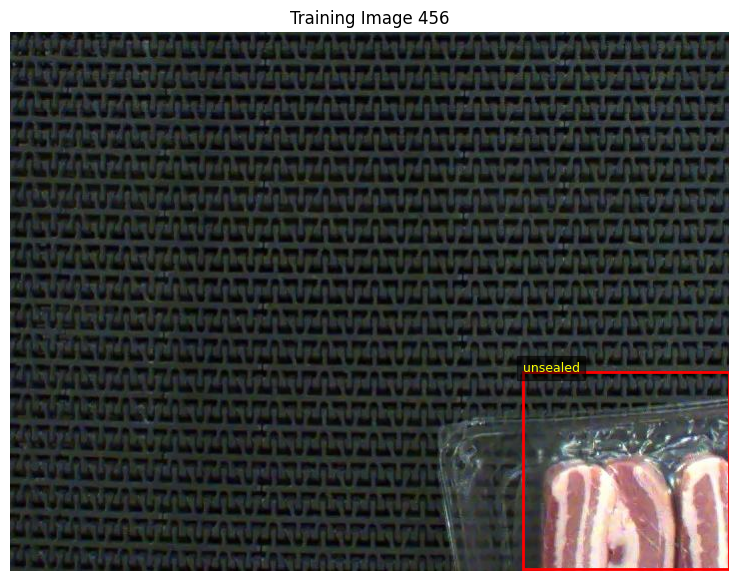

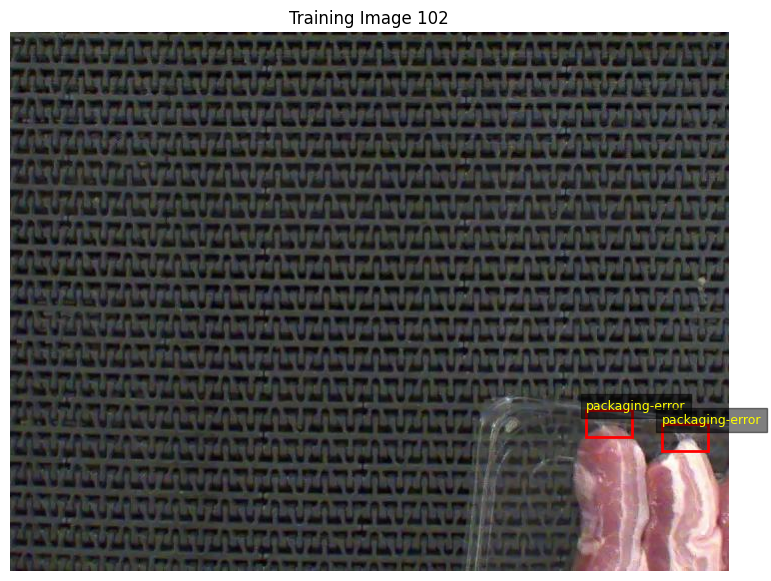

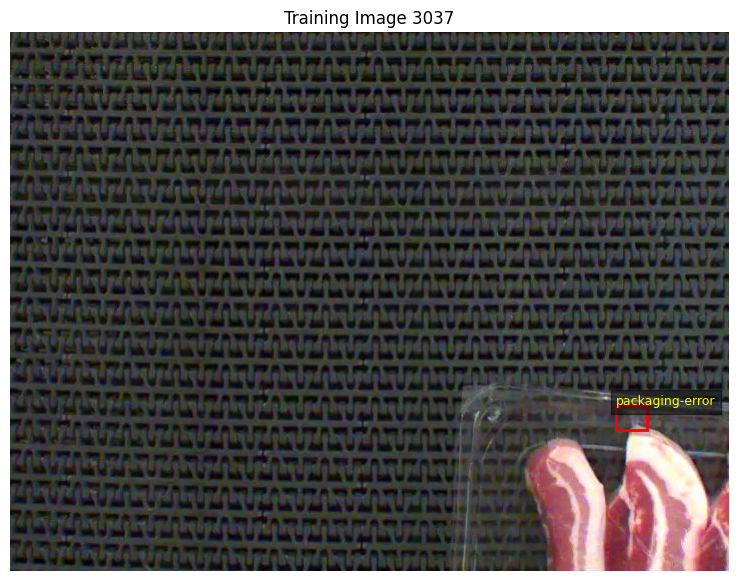

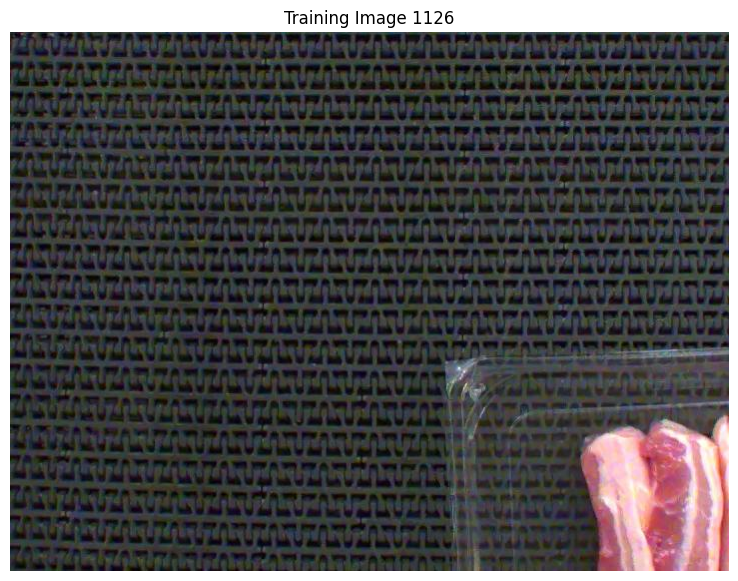

In [4]:

# Visualise original images with converted ground-truth boxes.

def display_annotation(index, dataset, title=None):
    """Display an image with its ground-truth bounding boxes and labels.

    Args:
        index: Integer index of the image within the dataset.
        dataset: YOLO detection dataset containing images and annotations.
        title: Optional title displayed above the image.

    Returns:
        None. The annotated image is displayed using Matplotlib.

    Raises:
        IndexError: If the image index is outside the dataset range.
    """
    image, target = dataset[index]

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(image.permute(1, 2, 0).numpy())

    for box, label in zip(
        target["boxes"],
        target["labels"],
    ):
        x1, y1, x2, y2 = box.tolist()

        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )

        ax.add_patch(rectangle)

        ax.text(
            x1,
            y1,
            class_names[int(label)],
            color="yellow",
            fontsize=9,
            bbox={
                "facecolor": "black",
                "alpha": 0.5,
            },
        )

    ax.set_title(title or f"Image index {index}")
    ax.axis("off")

    plt.show()
    plt.close(fig)


first_image, first_target = train_dataset[0]

print("Image tensor shape:", first_image.shape)
print("Bounding boxes:", first_target["boxes"])
print("Class labels:", first_target["labels"])

display_annotation(
    0,
    train_dataset,
    "YOLO-to-RetinaNet Annotation Verification",
)

# Preserve reproducible random inspection of five images.
sample_indices = random.sample(
    range(len(train_dataset)),
    min(5, len(train_dataset)),
)

for index in sample_indices:
    display_annotation(
        index,
        train_dataset,
        f"Training Image {index}",
    )



## 2. Loading the Saved RetinaNet Checkpoint

The original experiment used RetinaNet ResNet50-FPN V2 with a modified classification head.

The detector used six classification outputs, corresponding to five defect classes and a reserved background index in the original label convention.

The model architecture is reconstructed, and the saved `best.pt` state dictionary is loaded without downloading pretrained training weights or performing optimisation.


In [5]:

# Reconstruct the original model and strictly load its saved checkpoint.

retinanet = load_experiment_model(
    project_root=project_root,
    run_name="retinanet_baseline",
    device=device,
)

retinanet.eval()

output_classes = (
    retinanet.head.classification_head.num_classes
)

assert output_classes == NUM_CLASSES + 1

print("RetinaNet checkpoint loaded successfully.")
print("Number of output classes:", output_classes)
print("Device:", device)
print("Checkpoint:", checkpoint_path)


RetinaNet checkpoint loaded successfully.
Number of output classes: 6
Device: cuda
Checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1/best.pt



## 3. Original Training History

The original experiment recorded training loss, validation mAP@50 and validation mAP@50:95 across epochs.

Training history is loaded from existing saved experiment files when available. The notebook does not reconstruct missing historical values from the final model checkpoint.

If the run folder does not contain an exported history, the original training notebook remains the source of the historical graphs until those records are archived separately.


In [6]:

# Search for genuine historical RetinaNet training records and figures.

history_candidates = [
    run_dir / "history.csv",
    run_dir / "training_history.csv",
    run_dir / "results.csv",
    run_dir / "history.json",
    run_dir / "training_history.json",
]

history_path = next(
    (path for path in history_candidates if path.is_file()),
    None,
)

history_df = None

if history_path is not None:
    if history_path.suffix.lower() == ".csv":
        history_df = pd.read_csv(history_path)
    else:
        with history_path.open("r", encoding="utf-8") as file:
            content = json.load(file)

        if isinstance(content, dict) and "history" in content:
            content = content["history"]

        history_df = pd.DataFrame(content)

    history_df.columns = history_df.columns.str.strip()

    print("Training-history source:", history_path)
    display(history_df.head())

    # Use recorded epoch data only, without reconstructing missing values.
    if "epoch" not in history_df.columns:
        history_df = history_df.copy()
        history_df["epoch"] = np.arange(1, len(history_df) + 1)

    if "train_loss" in history_df.columns:
        figure = plot_training_history(
            history_df,
            metric_columns={"train_loss": "Training Loss"},
            title="RetinaNet Training Loss",
            ylabel="Loss",
        )
        plt.show()
        plt.close(figure)

    map_columns = {
        column: label
        for column, label in {
            "val_map": "mAP@50:95",
            "val_map50": "mAP@50",
        }.items()
        if column in history_df.columns
    }

    if map_columns:
        figure = plot_training_history(
            history_df,
            metric_columns=map_columns,
            title="RetinaNet Validation Performance",
            ylabel="mAP",
        )
        plt.show()
        plt.close(figure)

else:
    print(
        "No exported epoch-by-epoch training history was found. "
        "Historical loss and validation mAP curves cannot be "
        "reconstructed from the saved best checkpoint."
    )

# Display any authentic, previously exported training figures.
history_figures = [
    "training_loss.png",
    "train_loss.png",
    "loss_curve.png",
    "validation_map.png",
    "val_map.png",
    "training_history.png",
]

found_history_figures = []

for filename in history_figures:
    figure_path = run_dir / filename

    if figure_path.is_file():
        found_history_figures.append(filename)

        print("Original saved figure:", filename)
        figure = show_saved_figure(figure_path)
        plt.show()
        plt.close(figure)

if not found_history_figures:
    print(
        "No matching historical training PNG was found in the run folder."
    )

print("Best saved checkpoint epoch: 5 of 15 (original experiment).")


No exported epoch-by-epoch training history was found. Historical loss and validation mAP curves cannot be reconstructed from the saved best checkpoint.
No matching historical training PNG was found in the run folder.
Best saved checkpoint epoch: 5 of 15 (original experiment).



## 4. Validation Predictions

The selected RetinaNet checkpoint is evaluated on the cleaned five-class validation split.

Predictions and ground-truth targets are collected once and reused for all subsequent analyses. This avoids repeated inference and ensures consistent inputs for AP calculation, threshold comparisons and confusion matrices.


In [7]:

# Run inference once on the complete five-class validation split.

@torch.inference_mode()
def collect_predictions(model, data_loader, inference_device):
    """Collect detection predictions and matching ground-truth targets.

    Args:
        model: Trained RetinaNet object detection model.
        data_loader: DataLoader providing images and annotation targets.
        inference_device: PyTorch device used for model inference.

    Returns:
        Tuple containing two lists:
            - Predictions with bounding boxes, confidence scores and labels.
            - Ground-truth targets with bounding boxes and labels.
        All tensors are transferred to the CPU.
    """

    model.eval()

    predictions = []
    targets = []

    for images, batch_targets in data_loader:
        images_device = [
            image.to(inference_device)
            for image in images
        ]

        batch_predictions = model(images_device)

        for prediction, target in zip(
            batch_predictions,
            batch_targets,
        ):
            predictions.append({
                "boxes": prediction["boxes"].detach().cpu(),
                "scores": prediction["scores"].detach().cpu(),
                "labels": prediction["labels"].detach().cpu(),
            })

            targets.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu(),
            })

    return predictions, targets


predictions_all, targets_all = collect_predictions(
    retinanet,
    valid_loader,
    device,
)

assert len(predictions_all) == len(valid_dataset)
assert len(targets_all) == len(valid_dataset)

print("Validation images evaluated:", len(predictions_all))
print("Prediction records:", len(predictions_all))
print("Ground-truth records:", len(targets_all))
print("Checkpoint:", checkpoint_path)

# Release the model after collecting all validation predictions.
del retinanet
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Validation images evaluated: 123
Prediction records: 123
Ground-truth records: 123
Checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1/best.pt



## 5. COCO-Style Validation Metrics

Detection accuracy is evaluated using TorchMetrics and the standard COCO intersection-over-union thresholds.

The following measurements are reported:
- Overall mAP@50:95.
- Overall mAP@50.
- Overall mAP@75.
- Mean average recall at 100 detections.
- Per-class AP@50 and AP@50:95.

These values are calculated directly from the existing checkpoint predictions, rather than entered manually.


In [8]:

# Calculate COCO-style AP and recall from saved-checkpoint predictions.

metric_5095 = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

metric_50 = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
    iou_thresholds=[0.50],
)

metric_5095.update(predictions_all, targets_all)
metric_50.update(predictions_all, targets_all)

results_5095 = metric_5095.compute()
results_50 = metric_50.compute()

overall_ap_df = pd.DataFrame([{
    "mAP@50:95": float(results_5095["map"]),
    "mAP@50": float(results_5095["map_50"]),
    "mAP@75": float(results_5095["map_75"]),
    "mAR@100": float(results_5095["mar_100"]),
}])

# Associate measured AP values with their actual one-based class IDs.
ap_5095 = {
    int(class_id): float(ap)
    for class_id, ap in zip(
        results_5095["classes"],
        results_5095["map_per_class"],
    )
}

ap_50 = {
    int(class_id): float(ap)
    for class_id, ap in zip(
        results_50["classes"],
        results_50["map_per_class"],
    )
}

per_class_df = pd.DataFrame([
    {
        "Class": name,
        "AP@50": ap_50.get(class_id, np.nan),
        "AP@50:95": ap_5095.get(class_id, np.nan),
    }
    for class_id, name in class_names.items()
])

print("OVERALL RETINANET VALIDATION PERFORMANCE")
display(overall_ap_df.round(4))

print("\nPER-CLASS AVERAGE PRECISION")
display(per_class_df.round(4))

# Compare against the original checkpoint evaluation.
reference_map = 0.2018
observed_map = float(overall_ap_df.iloc[0]["mAP@50:95"])

print("\nORIGINAL mAP@50:95 REPRODUCIBILITY")
print("Original:", reference_map)
print("Integrated:", round(observed_map, 4))
print("Within tolerance:", abs(observed_map - reference_map) <= 0.005)


OVERALL RETINANET VALIDATION PERFORMANCE


,mAP@50:95,mAP@50,mAP@75,mAR@100
0,0.2018,0.3369,0.2141,0.3204



PER-CLASS AVERAGE PRECISION


,Class,AP@50,AP@50:95
0,loose-meat,0.4728,0.3173
1,packaging-error,0.1677,0.0415
2,twisted-meat,0.1683,0.0842
3,unsealed,0.8758,0.5662
4,wrinkle,0.0000,0.0000



ORIGINAL mAP@50:95 REPRODUCIBILITY
Original: 0.2018
Integrated: 0.2018
Within tolerance: True



## 6. Confidence-Threshold Optimisation

The original experiment investigated how the confidence threshold affects detection precision, recall and F1-score.

A confidence sweep from 0.001 to 0.999 is performed using 200 candidate thresholds and an IoU matching threshold of 0.50.

The threshold producing the highest micro-averaged F1-score on the validation set is selected for detailed analysis.

This threshold is selected using validation data only. It does not represent independent test performance.

Confidence-threshold optimisation retains the original independent per-class IoU matching method. The shared metrics module is used to calculate precision, recall and F1-score.

BEST VALIDATION CONFIDENCE THRESHOLD
Matching method: independent per-class IoU matching
Threshold: 0.758
TP: 70
FP: 7
FN: 54
Precision: 0.9091
Recall: 0.5645
F1: 0.6965


,Threshold,TP,FP,FN,Precision,Recall,F1
153,0.7683,70,7,54,0.9091,0.5645,0.6965
151,0.7583,70,7,54,0.9091,0.5645,0.6965
152,0.7633,70,7,54,0.9091,0.5645,0.6965
154,0.7733,69,7,55,0.9079,0.5565,0.6900
155,0.7783,69,7,55,0.9079,0.5565,0.6900
156,0.7834,69,7,55,0.9079,0.5565,0.6900
150,0.7533,70,9,54,0.8861,0.5645,0.6897
102,0.5125,74,17,50,0.8132,0.5968,0.6884
103,0.5176,74,17,50,0.8132,0.5968,0.6884
147,0.7382,70,10,54,0.8750,0.5645,0.6863


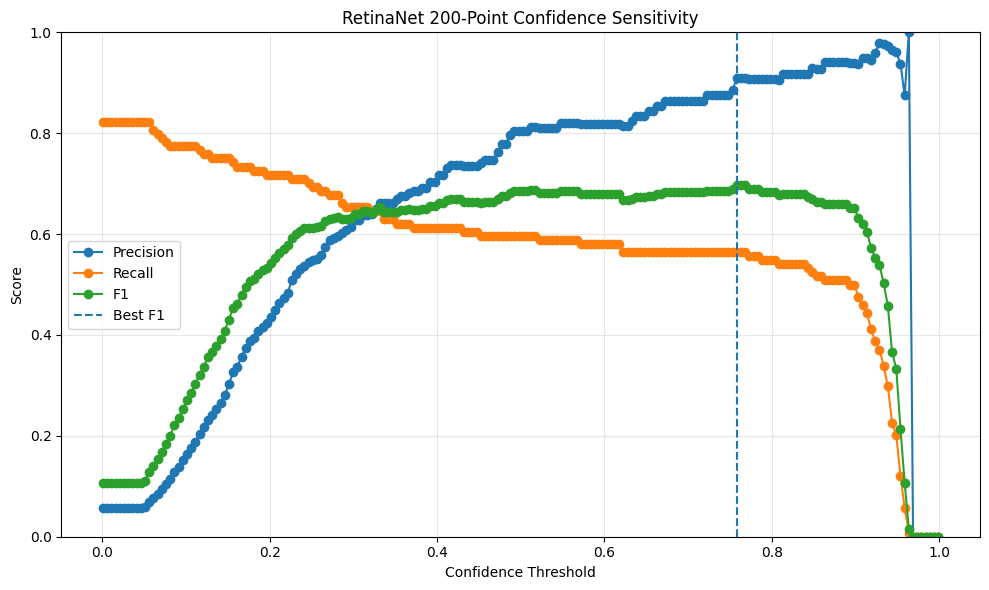


ORIGINAL SELECTED THRESHOLD
Expected approximately: 0.758
Original selected F1: 0.6965


In [9]:

# Preserve the original class-specific matching used in the 200-point sweep.

def calculate_class_counts(
    predictions,
    targets,
    threshold,
    class_id,
    iou_threshold=0.50,
):
    """Calculate class-specific detection counts using greedy IoU matching.

    Args:
        predictions: List of prediction dictionaries containing boxes,
            confidence scores and predicted class labels.
        targets: List of ground-truth dictionaries containing boxes
            and actual class labels.
        threshold: Minimum confidence required to retain a prediction.
        class_id: One-based defect class ID being evaluated.
        iou_threshold: Minimum intersection-over-union required to
            match a prediction with a ground-truth object.

    Returns:
        Dictionary containing:
            - TP: Correctly matched predictions for the class.
            - FP: Predictions not matched to a same-class object.
            - FN: Ground-truth objects without a matching prediction.
            - Predictions: Number of predictions accepted after
              confidence filtering.
    """
    tp = fp = fn = accepted = 0

    for prediction, target in zip(predictions, targets):
        keep = (
            (prediction["scores"] >= threshold)
            & (prediction["labels"] == class_id)
        )

        pred_boxes = prediction["boxes"][keep]
        pred_scores = prediction["scores"][keep]

        gt_boxes = target["boxes"][
            target["labels"] == class_id
        ]

        accepted += len(pred_boxes)

        # Match high-confidence predictions to unused same-class objects.
        order = torch.argsort(
            pred_scores,
            descending=True,
        )

        pred_boxes = pred_boxes[order]
        matched_gt = set()

        for pred_box in pred_boxes:
            if len(gt_boxes) == 0:
                fp += 1
                continue

            ious = box_iou(
                pred_box.unsqueeze(0),
                gt_boxes,
            )[0]

            for matched_index in matched_gt:
                ious[matched_index] = -1

            best_iou, best_index = ious.max(0)
            best_index = int(best_index)

            if float(best_iou) >= iou_threshold:
                tp += 1
                matched_gt.add(best_index)
            else:
                fp += 1

        fn += len(gt_boxes) - len(matched_gt)

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Predictions": accepted,
    }


def calculate_class_specific_metrics(
    predictions,
    targets,
    threshold,
    iou_threshold=0.50,
):
    """Summarise detection performance using independent class matching.

    Each defect class is evaluated separately before overall precision,
    recall and F1-score are calculated from the combined detection counts.

    Args:
        predictions: List of prediction dictionaries containing boxes,
            confidence scores and class labels.
        targets: List of ground-truth dictionaries containing boxes
            and actual class labels.
        threshold: Minimum confidence required to accept a prediction.
        iou_threshold: Minimum IoU for matching a detection to a
            ground-truth object of the same class.

    Returns:
        Tuple containing:
            - Overall metrics dictionary with threshold, TP, FP, FN,
              precision, recall and F1-score.
            - List of per-class metric dictionaries containing
              detection counts and performance scores.
    """
    class_rows = []
    total_tp = total_fp = total_fn = 0

    for class_id, name in class_names.items():
        counts = calculate_class_counts(
            predictions,
            targets,
            threshold,
            class_id,
            iou_threshold,
        )

        scores = precision_recall_f1(
            counts["TP"],
            counts["FP"],
            counts["FN"],
        )

        class_rows.append({
            "Threshold": float(threshold),
            "Class": name,
            **counts,
            **scores,
        })

        total_tp += counts["TP"]
        total_fp += counts["FP"]
        total_fn += counts["FN"]

    overall = {
        "Threshold": float(threshold),
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        **precision_recall_f1(total_tp, total_fp, total_fn),
    }

    return overall, class_rows


# Repeat the exact original 200 candidate confidence thresholds.
candidate_thresholds = np.linspace(
    0.001,
    0.999,
    200,
)

sweep_rows = []

for threshold in candidate_thresholds:
    overall, _ = calculate_class_specific_metrics(
        predictions_all,
        targets_all,
        float(threshold),
        iou_threshold=0.50,
    )

    sweep_rows.append(overall)

sweep_df = pd.DataFrame(sweep_rows)

best_pr = select_best_threshold(
    sweep_df,
    metric="F1",
)

BEST_THRESHOLD = float(best_pr["Threshold"])

print("BEST VALIDATION CONFIDENCE THRESHOLD")
print("Matching method: independent per-class IoU matching")
print(f"Threshold: {BEST_THRESHOLD:.3f}")
print(f"TP: {int(best_pr['TP'])}")
print(f"FP: {int(best_pr['FP'])}")
print(f"FN: {int(best_pr['FN'])}")
print(f"Precision: {best_pr['Precision']:.4f}")
print(f"Recall: {best_pr['Recall']:.4f}")
print(f"F1: {best_pr['F1']:.4f}")

display(
    sweep_df.sort_values(
        "F1",
        ascending=False,
    ).head(10).round(4)
)

# Display the fine confidence sweep as an additional diagnostic graph.
figure = plot_threshold_metrics(
    sweep_df,
    metric_columns=["Precision", "Recall", "F1"],
    title="RetinaNet 200-Point Confidence Sensitivity",
    selected_thresholds={
        "Best F1": BEST_THRESHOLD,
    },
)
plt.show()
plt.close(figure)

print("\nORIGINAL SELECTED THRESHOLD")
print("Expected approximately: 0.758")
print("Original selected F1: 0.6965")



## 7. Confusion Matrix and Per-Class Detection Metrics

A six-class confusion matrix is calculated at the validation-selected confidence threshold.

The matrix includes the five defect classes and one background category. Rows represent predicted classes, while columns represent true classes.

The background row records missed ground-truth objects, and the background column records unmatched detections.

Per-class precision, recall and F1-score are derived from the same confusion matrix.

Confusion matrices use the shared global IoU matcher, which allows incorrect-class predictions to be represented as off-diagonal entries. These counts may differ from Section 6 because the matching methods are not identical.

GLOBAL-MATCHING CONFUSION MATRIX
Selected confidence threshold: 0.758


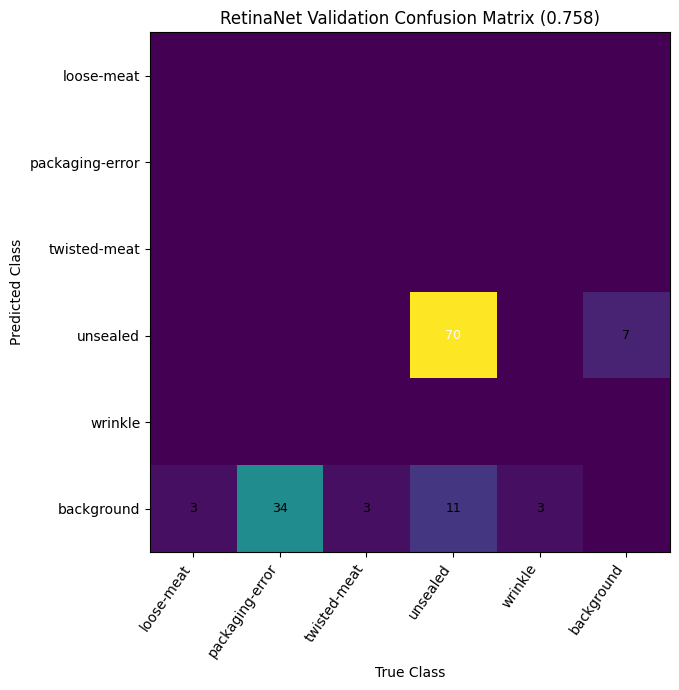

,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle,background
loose-meat,0,0,0,0,0,0
packaging-error,0,0,0,0,0,0
twisted-meat,0,0,0,0,0,0
unsealed,0,0,0,70,0,7
wrinkle,0,0,0,0,0,0
background,3,34,3,11,3,0



GLOBAL-MATCHING OVERALL METRICS


,Threshold,TP,FP,FN,Precision,Recall,F1,Macro-Precision,Macro-Recall,Macro-F1
0,0.7583,70,7,54,0.9091,0.5645,0.6965,0.1818,0.1728,0.1772



PER-CLASS DETECTION METRICS


,Class,TP,FP,FN,Precision,Recall,F1
0,loose-meat,0,0,3,0.0000,0.0000,0.0000
1,packaging-error,0,0,34,0.0000,0.0000,0.0000
2,twisted-meat,0,0,3,0.0000,0.0000,0.0000
3,unsealed,70,7,11,0.9091,0.8642,0.8861
4,wrinkle,0,0,3,0.0000,0.0000,0.0000



COMBINED PER-CLASS VALIDATION RESULTS


,Class,AP@50,AP@50:95,TP,FP,FN,Precision,Recall,F1
0,loose-meat,0.4728,0.3173,0,0,3,0.0000,0.0000,0.0000
1,packaging-error,0.1677,0.0415,0,0,34,0.0000,0.0000,0.0000
2,twisted-meat,0.1683,0.0842,0,0,3,0.0000,0.0000,0.0000
3,unsealed,0.8758,0.5662,70,7,11,0.9091,0.8642,0.8861
4,wrinkle,0.0000,0.0000,0,0,3,0.0000,0.0000,0.0000



MATCHING-METHOD COMPARISON
Independent per-class TP: 70
Global confusion-matrix TP: 70
The methods may differ because global matching allows incorrect-class matches.


In [10]:

# Evaluate the selected threshold with global, cross-class IoU matching.

selected_overall, class_metrics_df, confusion_matrix = (
    evaluate_thresholds(
        predictions=predictions_all,
        targets=targets_all,
        thresholds=[BEST_THRESHOLD],
        class_names=CLASS_NAMES,
        iou_threshold=0.50,
        label_offset=1,
    )
)

# The shared evaluation function returns lists of threshold results.
selected_summary = selected_overall.iloc[0]

print("GLOBAL-MATCHING CONFUSION MATRIX")
print(f"Selected confidence threshold: {BEST_THRESHOLD:.3f}")

figure, ax = plt.subplots(figsize=(9, 7))

plot_confusion_matrix(
    matrix=confusion_matrix[0],
    class_names=CLASS_NAMES,
    title=f"RetinaNet Validation Confusion Matrix ({BEST_THRESHOLD:.3f})",
    ax=ax,
    cmap="viridis",
)

plt.tight_layout()
plt.show()
plt.close(figure)

display(
    pd.DataFrame(
        confusion_matrix[0],
        index=MATRIX_LABELS,
        columns=MATRIX_LABELS,
    )
)

print("\nGLOBAL-MATCHING OVERALL METRICS")
display(selected_overall.round(4))

print("\nPER-CLASS DETECTION METRICS")
class_metrics_df = class_metrics_df.drop(
    columns=["Threshold"],
)

display(class_metrics_df.round(4))

# Combine fixed-threshold metrics with separately calculated AP.
full_class_results = pd.merge(
    per_class_df,
    class_metrics_df,
    on="Class",
    how="left",
)

print("\nCOMBINED PER-CLASS VALIDATION RESULTS")
display(full_class_results.round(4))

# Show the methodological difference instead of masking it.
print("\nMATCHING-METHOD COMPARISON")
print(
    "Independent per-class TP:",
    int(best_pr["TP"]),
)
print(
    "Global confusion-matrix TP:",
    int(selected_summary["TP"]),
)
print(
    "The methods may differ because global matching allows "
    "incorrect-class matches."
)



## 8. Confidence-Threshold Comparison

The original experiment also compared five selected confidence thresholds: 0.10, 0.25, 0.50, 0.70 and 0.849.

This analysis retains the original comparison thresholds, allowing performance to be examined across a range of operating points.

For each threshold, the notebook reports:
- Overall TP, FP, FN, precision, recall and F1.
- Per-class accepted predictions, TP, FP, FN, precision, recall and F1.
- Correct detections by class.
- Per-class recall.
- Precision, recall and F1 versus confidence threshold.

The threshold comparison uses the existing checkpoint predictions and does not rerun training.


ORIGINAL PER-CLASS MATCHING: OVERALL THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.100,96,501,28,0.1608,0.7742,0.2663
1,0.250,86,71,38,0.5478,0.6935,0.6121
2,0.500,74,18,50,0.8043,0.5968,0.6852
3,0.700,70,11,54,0.8642,0.5645,0.6829
4,0.849,65,5,59,0.9286,0.5242,0.6701



ORIGINAL PER-CLASS MATCHING: PER-CLASS RESULTS


,Threshold,Class,TP,FP,FN,Predictions,Precision,Recall,F1
0,0.100,loose-meat,3,63,0,66,0.0455,1.0000,0.0870
1,0.100,packaging-error,17,116,17,133,0.1278,0.5000,0.2036
2,0.100,twisted-meat,1,96,2,97,0.0103,0.3333,0.0200
3,0.100,unsealed,75,226,6,301,0.2492,0.9259,0.3927
4,0.100,wrinkle,0,0,3,0,0.0000,0.0000,0.0000
5,0.250,loose-meat,0,0,3,0,0.0000,0.0000,0.0000
6,0.250,packaging-error,11,25,23,36,0.3056,0.3235,0.3143
7,0.250,twisted-meat,1,1,2,2,0.5000,0.3333,0.4000
8,0.250,unsealed,74,45,7,119,0.6218,0.9136,0.7400
9,0.250,wrinkle,0,0,3,0,0.0000,0.0000,0.0000



CORRECT DETECTIONS BY CLASS


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,3,17,1,75,0
0.250,0,11,1,74,0
0.500,0,3,0,71,0
0.700,0,0,0,70,0
0.849,0,0,0,65,0



PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,1.0,0.5000,0.3333,0.9259,0.0
0.250,0.0,0.3235,0.3333,0.9136,0.0
0.500,0.0,0.0882,0.0000,0.8765,0.0
0.700,0.0,0.0000,0.0000,0.8642,0.0
0.849,0.0,0.0000,0.0000,0.8025,0.0


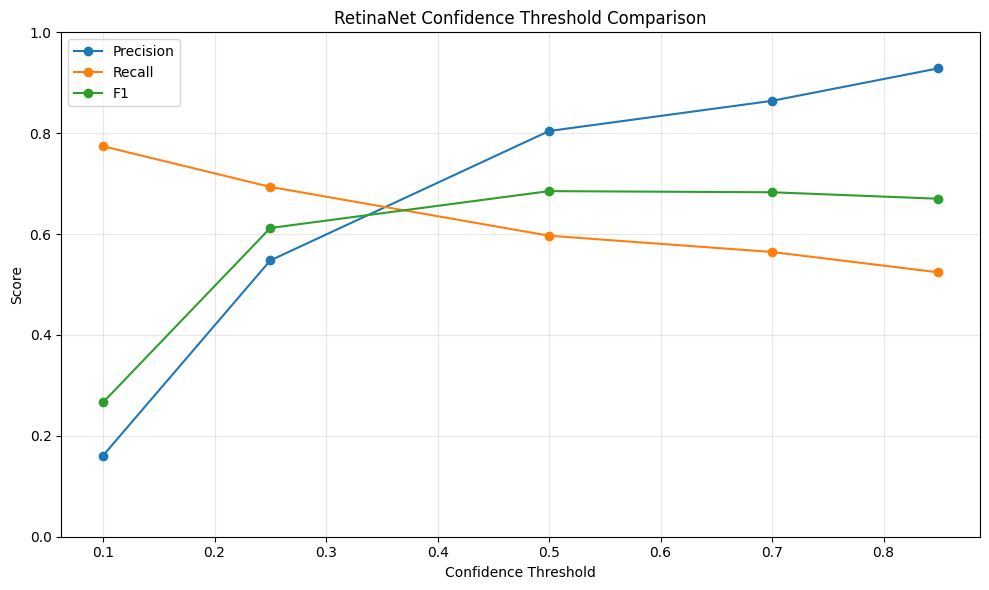


BEST OF FIVE ORIGINAL THRESHOLDS
Threshold: 0.500
Precision: 0.8043
Recall: 0.5968
F1: 0.6852

GLOBAL-MATCHING THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.100,92,505,32,0.1541,0.7419,0.2552
1,0.250,85,72,39,0.5414,0.6855,0.6050
2,0.500,74,18,50,0.8043,0.5968,0.6852
3,0.700,70,11,54,0.8642,0.5645,0.6829
4,0.849,65,5,59,0.9286,0.5242,0.6701


In [11]:

# Compare the five original confidence thresholds using both matching methods.

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

# Preserve the original independent per-class threshold tables.
legacy_overall_rows = []
legacy_class_rows = []

for threshold in THRESHOLDS:
    overall, class_rows = calculate_class_specific_metrics(
        predictions_all,
        targets_all,
        threshold,
        IOU_THRESHOLD,
    )

    legacy_overall_rows.append(overall)
    legacy_class_rows.extend(class_rows)

overall_df = pd.DataFrame(legacy_overall_rows)
class_df = pd.DataFrame(legacy_class_rows)

print("ORIGINAL PER-CLASS MATCHING: OVERALL THRESHOLD COMPARISON")
display(overall_df.round(4))

print("\nORIGINAL PER-CLASS MATCHING: PER-CLASS RESULTS")
display(class_df.round(4))

print("\nCORRECT DETECTIONS BY CLASS")
display(correct_detections_table(class_df))

print("\nPER-CLASS RECALL")
display(per_class_recall_table(class_df).round(4))

legacy_figure = plot_threshold_metrics(
    overall_df,
    metric_columns=["Precision", "Recall", "F1"],
    title="RetinaNet Confidence Threshold Comparison",
)

plt.show()
plt.close(legacy_figure)

best_tested_row = select_best_threshold(
    overall_df,
    metric="F1",
)

print("\nBEST OF FIVE ORIGINAL THRESHOLDS")
print(f"Threshold: {best_tested_row['Threshold']:.3f}")
print(f"Precision: {best_tested_row['Precision']:.4f}")
print(f"Recall: {best_tested_row['Recall']:.4f}")
print(f"F1: {best_tested_row['F1']:.4f}")

# Calculate a separate global-matching comparison for consistency.
global_overall_df, global_class_df, matrices = evaluate_thresholds(
    predictions=predictions_all,
    targets=targets_all,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    iou_threshold=IOU_THRESHOLD,
    label_offset=1,
)

print("\nGLOBAL-MATCHING THRESHOLD COMPARISON")
display(global_overall_df[
    ["Threshold", "TP", "FP", "FN", "Precision", "Recall", "F1"]
].round(4))



## 9. Confusion Matrices Across Confidence Thresholds

Six-class confusion matrices are generated at the same five confidence thresholds.

Comparing these matrices illustrates how the confidence threshold changes the balance between correct detections, false positives and missed defects.

The matrices share a common colour scale and preserve the original class ordering. A corresponding table records the diagonal counts, representing correctly classified and localised defects.


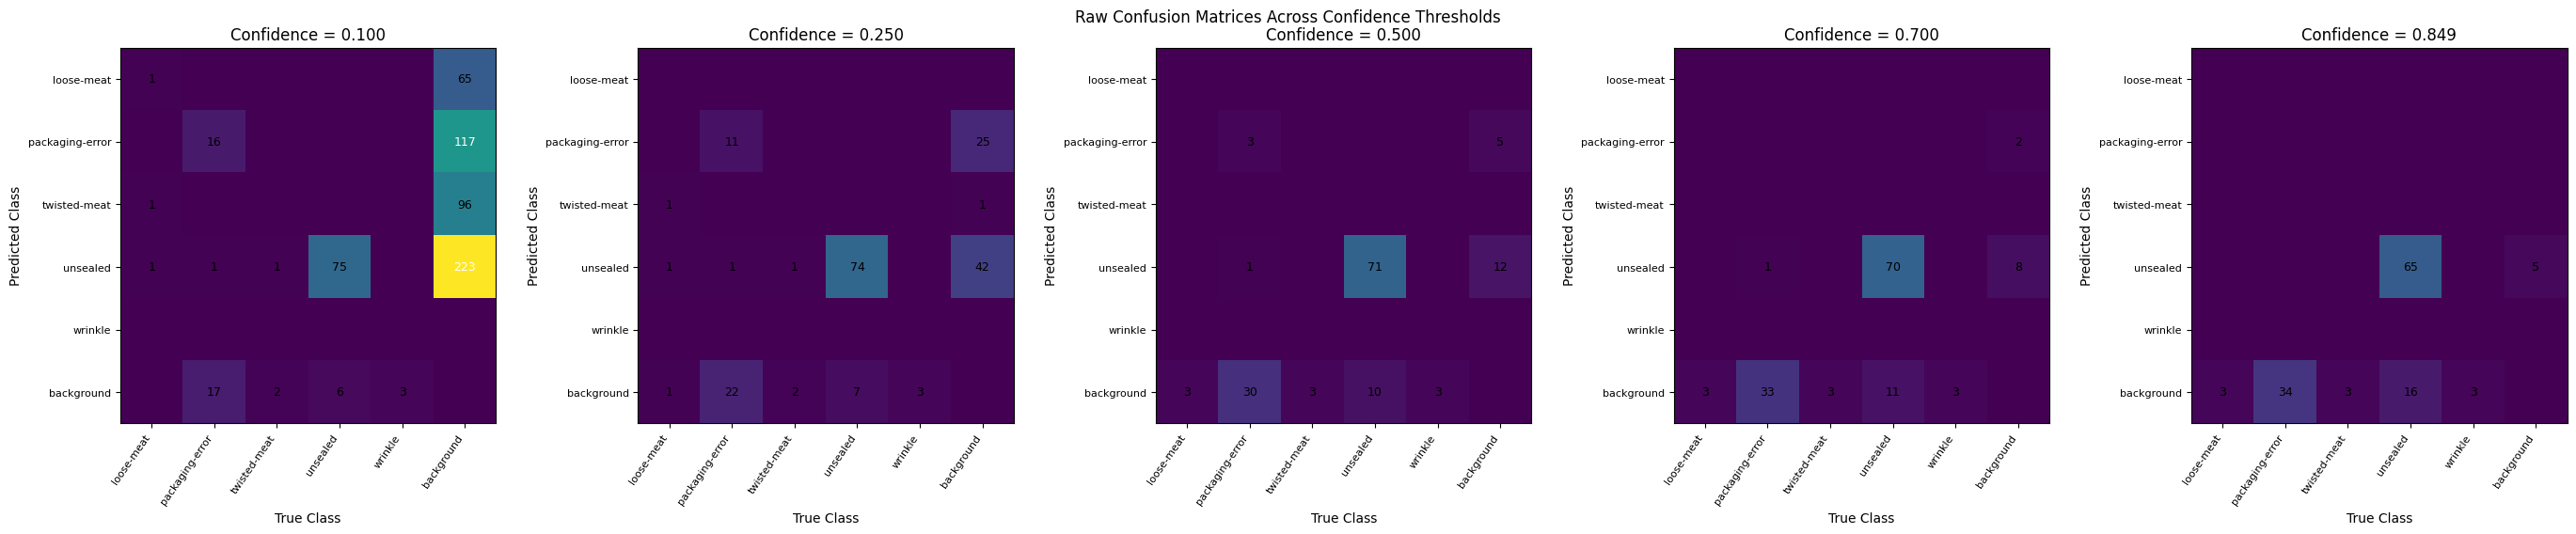

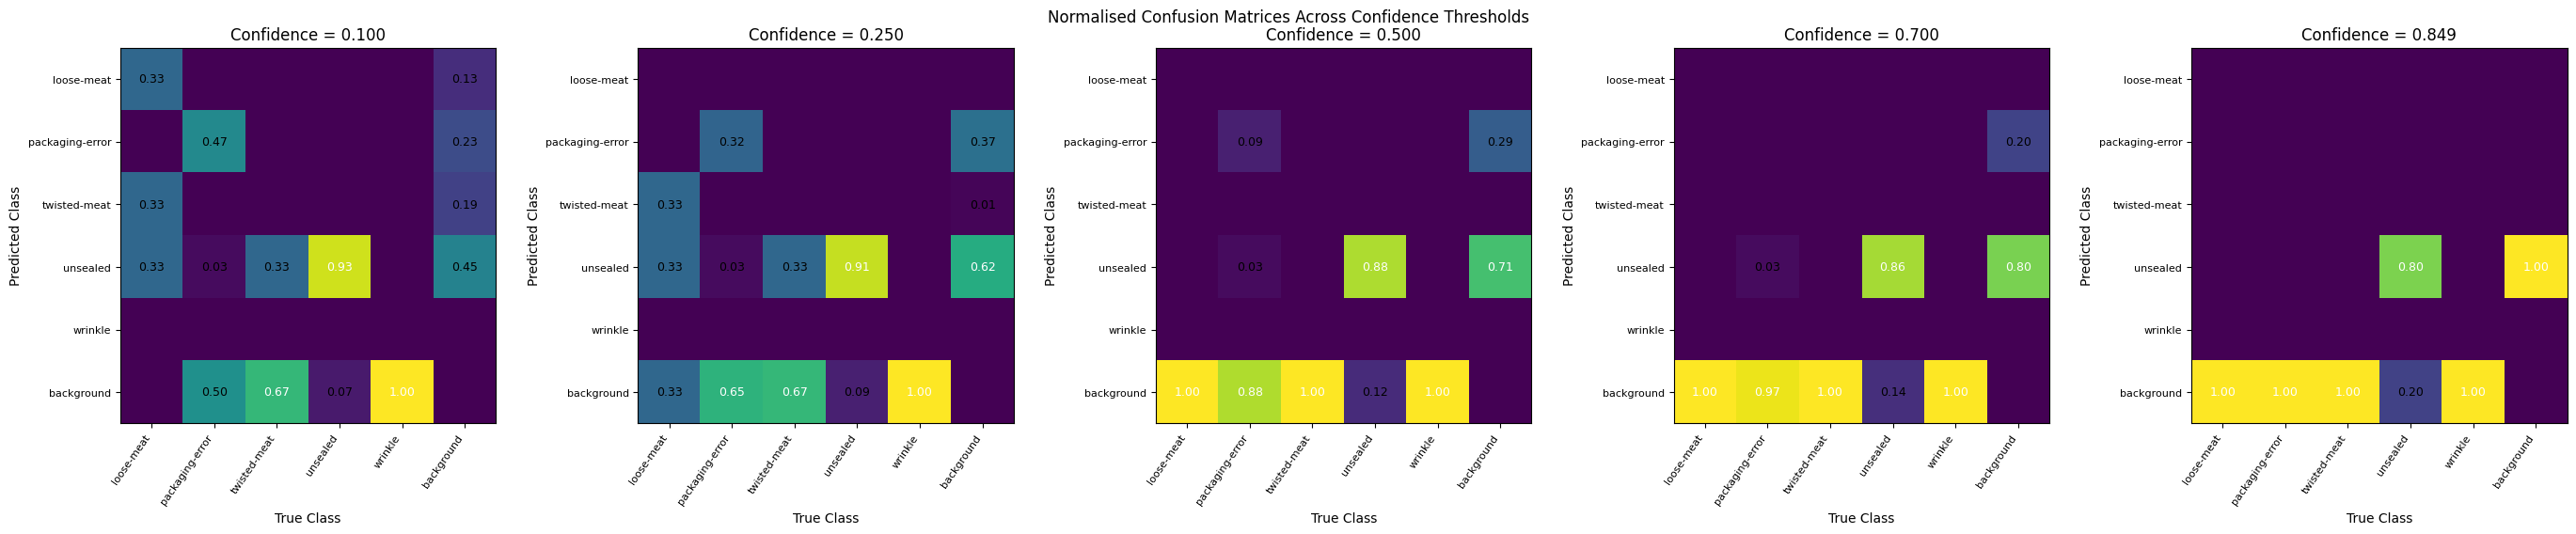

CORRECT DETECTIONS BY CONFIDENCE THRESHOLD


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,1,16,0,75,0
0.250,0,11,0,74,0
0.500,0,3,0,71,0
0.700,0,0,0,70,0
0.849,0,0,0,65,0



GLOBAL PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,0.3333,0.4706,0.0,0.9259,0.0
0.250,0.0000,0.3235,0.0,0.9136,0.0
0.500,0.0000,0.0882,0.0,0.8765,0.0
0.700,0.0000,0.0000,0.0,0.8642,0.0
0.849,0.0000,0.0000,0.0,0.8025,0.0


In [12]:

# Display the five original threshold-specific global confusion matrices.

raw_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=False,
    cmap="viridis",
)

plt.show()
plt.close(raw_figure)

# Include normalised versions for direct per-class comparison.
normalized_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=True,
    cmap="viridis",
)

plt.show()
plt.close(normalized_figure)

print("CORRECT DETECTIONS BY CONFIDENCE THRESHOLD")
display(
    correct_detections_table(global_class_df)
)

print("\nGLOBAL PER-CLASS RECALL")
display(
    per_class_recall_table(global_class_df).round(4)
)



## 10. Findings and Limitations

The preliminary RetinaNet experiment evaluates an alternative detection architecture using the original cleaned five-class dataset.

The existing trained checkpoint supports repeatable calculation of validation mAP, per-class AP, confidence-threshold performance and detection confusion matrices without retraining.

Training-history graphs represent a different form of evidence: they require the original recorded per-epoch loss and validation metrics. Those records must be preserved independently from the selected checkpoint.

The wrinkle class has insufficient independent validation support for reliable AP interpretation.

Confidence thresholds are selected and compared using validation data. Their performance should not be interpreted as independent test-set performance.

The subsequent four-class experiments provide a more appropriate basis for the final comparison among YOLOv8n, RetinaNet and Faster R-CNN.


In [13]:

# Summarise the preliminary experiment and verify key original results.

print("PRELIMINARY RETINANET EXPERIMENT COMPLETED")

print("\nDataset:", dataset_root)
print("Checkpoint:", checkpoint_path)
print("Validation images:", len(predictions_all))
print("Defect categories:", CLASS_NAMES)

print("\nOVERALL COCO-STYLE VALIDATION PERFORMANCE")
display(overall_ap_df.round(4))

print("\nPER-CLASS AVERAGE PRECISION")
display(per_class_df.round(4))

print("\nSELECTED CONFIDENCE THRESHOLD")
print(f"Threshold: {BEST_THRESHOLD:.4f}")
print(f"Independent-matching F1: {best_pr['F1']:.4f}")

print("\nPER-CLASS PERFORMANCE AT SELECTED THRESHOLD")
display(full_class_results.round(4))

print("\nFIVE-THRESHOLD COMPARISON")
display(overall_df.round(4))

# Historical reference values are verification targets, not live results.
reference_metrics = {
    "mAP@50:95": 0.2018,
    "mAP@50": 0.3369,
    "mAP@75": 0.2141,
    "mAR@100": 0.3204,
}

print("\nORIGINAL VALIDATION METRIC REPRODUCIBILITY")

all_ap_match = True

for metric_name, original_value in reference_metrics.items():
    observed = float(overall_ap_df.iloc[0][metric_name])
    matches = abs(observed - original_value) <= 0.005

    all_ap_match = all_ap_match and matches

    print(
        f"{metric_name}: "
        f"observed={observed:.4f}, "
        f"reference={original_value:.4f}, "
        f"within tolerance={matches}"
    )

print("\nORIGINAL CONFIDENCE OPTIMISATION REPRODUCIBILITY")

threshold_match = abs(BEST_THRESHOLD - 0.7583) <= 0.005
f1_match = abs(float(best_pr["F1"]) - 0.6965) <= 0.005

print("Best threshold matches:", threshold_match)
print("Best F1 matches:", f1_match)

if not all_ap_match or not threshold_match or not f1_match:
    print(
        "\nWARNING: Some results differ from the original experiment. "
        "Investigate before using updated numerical results."
    )
else:
    print("\nKey original RetinaNet results reproduced.")

print("\nTRAINING-HISTORY STATUS")
if history_df is None:
    print(
        "No saved epoch-history table was found. "
        "Retain historical training figures from the original "
        "executed training notebook if available."
    )
else:
    print("Training-history source:", history_path)

print("\nNo retraining was performed.")
print("No original dataset files or checkpoints were modified.")


PRELIMINARY RETINANET EXPERIMENT COMPLETED

Dataset: /content/gdrive_new/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_clean
Checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1/best.pt
Validation images: 123
Defect categories: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']

OVERALL COCO-STYLE VALIDATION PERFORMANCE


,mAP@50:95,mAP@50,mAP@75,mAR@100
0,0.2018,0.3369,0.2141,0.3204



PER-CLASS AVERAGE PRECISION


,Class,AP@50,AP@50:95
0,loose-meat,0.4728,0.3173
1,packaging-error,0.1677,0.0415
2,twisted-meat,0.1683,0.0842
3,unsealed,0.8758,0.5662
4,wrinkle,0.0000,0.0000



SELECTED CONFIDENCE THRESHOLD
Threshold: 0.7583
Independent-matching F1: 0.6965

PER-CLASS PERFORMANCE AT SELECTED THRESHOLD


,Class,AP@50,AP@50:95,TP,FP,FN,Precision,Recall,F1
0,loose-meat,0.4728,0.3173,0,0,3,0.0000,0.0000,0.0000
1,packaging-error,0.1677,0.0415,0,0,34,0.0000,0.0000,0.0000
2,twisted-meat,0.1683,0.0842,0,0,3,0.0000,0.0000,0.0000
3,unsealed,0.8758,0.5662,70,7,11,0.9091,0.8642,0.8861
4,wrinkle,0.0000,0.0000,0,0,3,0.0000,0.0000,0.0000



FIVE-THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.100,96,501,28,0.1608,0.7742,0.2663
1,0.250,86,71,38,0.5478,0.6935,0.6121
2,0.500,74,18,50,0.8043,0.5968,0.6852
3,0.700,70,11,54,0.8642,0.5645,0.6829
4,0.849,65,5,59,0.9286,0.5242,0.6701



ORIGINAL VALIDATION METRIC REPRODUCIBILITY
mAP@50:95: observed=0.2018, reference=0.2018, within tolerance=True
mAP@50: observed=0.3369, reference=0.3369, within tolerance=True
mAP@75: observed=0.2141, reference=0.2141, within tolerance=True
mAR@100: observed=0.3204, reference=0.3204, within tolerance=True

ORIGINAL CONFIDENCE OPTIMISATION REPRODUCIBILITY
Best threshold matches: True
Best F1 matches: True

Key original RetinaNet results reproduced.

TRAINING-HISTORY STATUS
No saved epoch-history table was found. Retain historical training figures from the original executed training notebook if available.

No retraining was performed.
No original dataset files or checkpoints were modified.
